### X Post Generator

In this we will make a llm based workflow where we will first generate a X post(tweet) on given topic, then we will evaluate that post , the evaluation step will generate a evaluation - approved or need approved and a feedback, if we get approved workflow will end but if not approved then it goes to a optimizer which will improve it further and pass again to evaluator, this will be a loop.
we will define maximum no. of iterations to prevent infinite loop.
we wll also keep storing tweet history and feedback history using reducer.

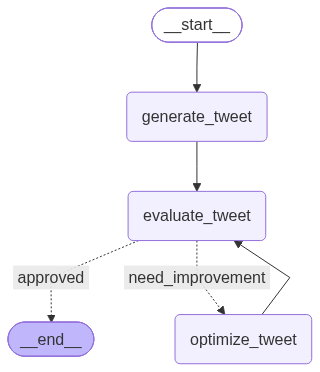

In [10]:
workflow

In [7]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated, Literal
from dotenv import load_dotenv
import operator

In [22]:
load_dotenv()
# generally we use different model for different purposes, like a model strong in creative generation can be used as generator model , but for initial
# learning i am using the same model
generator_model = ChatGroq(model='openai/gpt-oss-20b')
evaluator_model = ChatGroq(model='openai/gpt-oss-20b')
optimizer_model = ChatGroq(model='openai/gpt-oss-20b')

# for evaluation we required a structured output
class EvaluationSchema(BaseModel):
    evaluation: Literal['approved', 'need_improvement'] = Field(..., description='Final evaluation result')
    feedback: str = Field(...,description='feedback for the tweet')

structured_evaluator_model = evaluator_model.with_structured_output(EvaluationSchema, method='json_schema')

In [23]:
# define state
class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal['approved', 'need_improvement']
    feedback: str
    iteration: int
    max_iteration: int

    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [18]:
# create node functions
def generate_tweet(state: TweetState) -> TweetState:
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- first start with a sample with areas to improve
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]
    tweet = generator_model.invoke(messages).content
    return {'tweet':tweet, 'tweet_history': [tweet]}

def evaluate_tweet(state: TweetState) -> TweetState:
    # prompt
    messages = [
    SystemMessage(content="You are a ruthless,no-laugh-given Twitter critic. You evaluate tweets based on humor,originality,virality, and tweet format."),
    HumanMessage(content=f"""
    Evaluate the following tweet:

    Tweet: "{state['tweet']}"

    Use the criteria below to evaluate the tweet:

    1. Originality – Is this fresh, or have you seen it a hundred times before?  
    2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
    3. Punchiness – Is it short, sharp, and scroll-stopping?  
    4. Virality Potential – Would people retweet or share it?  
    5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

    Auto-reject if:
    - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
    - It exceeds 280 characters
    - It reads like a traditional setup-punchline joke
    - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

    ### Respond ONLY in structured format:
    - evaluation: "approved" or "needs_improvement"  
    - feedback: One paragraph explaining the strengths and weaknesses 
    """)
    ]
    response = structured_evaluator_model.invoke(messages)
    return {'evaluation':response.evaluation, 'feedback':response.feedback, 'feedback_history':[response.feedback]}

def optimize_tweet(state: TweetState) -> TweetState:
    # prompt ->
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
    Improve the tweet based on this feedback:
    "{state['feedback']}"

    Topic: "{state['topic']}"
    Original Tweet:
    {state['tweet']}

    Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
    """)
    ]
    response = optimizer_model.invoke(messages).content
    iteration = state['iteration'] + 1
    return {'tweet':response, 'iteration':iteration, 'tweet_history':[response]}

# routing function
def route_evaluation(state: TweetState) -> Literal['approved', 'need_improvement']:
    if state['evaluation']=='approved' or state['iteration']>=state['max_iteration']:
        return 'approved'
    else:
        return 'need_improvement'

In [9]:
# define graph
graph = StateGraph(TweetState)

# define nodes
graph.add_node('generate_tweet', generate_tweet)
graph.add_node('evaluate_tweet', evaluate_tweet)
graph.add_node('optimize_tweet', optimize_tweet)

# define edges
graph.add_edge(START, 'generate_tweet')
graph.add_edge('generate_tweet', 'evaluate_tweet')
graph.add_conditional_edges('evaluate_tweet', route_evaluation, {'approved':END, 'need_improvement':'optimize_tweet'})
graph.add_edge('optimize_tweet', 'evaluate_tweet')

# compile graph
workflow = graph.compile()

In [26]:
# testing
initial_state = {'topic': 'AI as a uncertain career', 'iteration':1, 'max_iteration':5}
workflow.invoke(initial_state)
# added '- first start with a sample with areas to improve' in the rules of generation so i can see it running in multiple iterations

{'topic': 'AI as a uncertain career',
 'tweet': 'AI is the future—my parents think it’s stable, until they say I should also work at a toaster factory. My LinkedIn says “AI Engineer,” my bank says “Unemployed.” #FutureOfWork #AI',
 'evaluation': 'approved',
 'feedback': 'The tweet cleverly juxtaposes the aspirational image of an AI engineer with the mundane reality of a toaster factory, delivering a punchy, under‑280‑character joke that feels fresh enough to spark shares. Its humor lands well, the brevity and hashtag placement make it scroll‑stopping, and the format is clean. The only slight drawback is that the AI/parents trope has appeared often, so the originality edge could be stronger. Overall, it meets all the criteria and is ready for approval.',
 'iteration': 2,
 'max_iteration': 5,
 'tweet_history': ['I told my parents AI is a stable career. They said, “Sure, as long as you get a job at a toaster factory.” Meanwhile, my LinkedIn says “AI Engineer” but my bank account says “Une